# 02. Разработка protocol-fixed pipeline и контрольный baseline

В `01_eda.ipynb` мы разобрали данные как объект исследования: workload оказались неоднородными, исходный split был сильно связан с workload, KPI присутствовали почти всегда, logs были доступны заметно хуже, target имели разную плотность, а предсобытийная динамика выглядела шумной. В этом notebook мы уже не продолжаем EDA, а собираем следующий слой работы: воспроизводимый pipeline, на котором дальше можно будет строить финальную модель.

Здесь мы фиксируем проектные решения и сразу превращаем их в исполняемый контур: какой contract считать входом, как разрезать данные на train/validation/test, какие target строить, какие feature groups считать минимальными, как выбирать threshold и какой baseline достаточно обучить, чтобы убедиться, что pipeline живой.

Baseline в конце намеренно остается простым. Его задача - не победить финальный контур и не быть главным результатом ВКР. Он нужен как acceptance test: pipeline обучается, validation управляет threshold, test не используется для настройки, predictions и metrics появляются в едином формате, а в данных есть ненулевой сигнал. В `03` этот же протокол станет основой для проверки финальной мультимодальной модели.


In [12]:
from __future__ import annotations

import argparse
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from dashboard.modeling.protocol_fixed_hades import DEFAULT_TARGETS, make_protocol_frame, make_target_matrix
from dashboard.training.baselines import _feature_sets as baseline_feature_sets

PROJECT_ROOT = Path.cwd()
RAW_DATA = PROJECT_ROOT / "raw_data"
CONTRACT_PATH = PROJECT_ROOT / "dashboard" / "artifacts" / "contract" / "strict_intensity_contract.csv.gz"
BASELINE_DIR = PROJECT_ROOT / "dashboard" / "artifacts" / "reports" / "protocol_fixed_baselines"

EXECUTION_MODE = "build_and_train"
ALLOWED_EXECUTION_MODES = {"build_and_train", "reuse_last_run"}

PIPELINE_CONFIG = {
    "split_protocol": "stratified_by_workload",
    "targets": list(DEFAULT_TARGETS),
    "seed": 43,
    "validation_seed": 43,
    "validation_fraction": 0.20,
    "fp_budget": 0.10,
    "max_tfidf_features": 2200,
    "max_iter": 700,
}

DISPLAY_TARGETS = ["y_warning", "horizon_30s", "horizon_60s", "horizon_120s", "horizon_300s"]

TARGET_LABELS = {
    "y_warning": "Горизонт 180 с",
    "horizon_30s": "Горизонт 30 с",
    "horizon_60s": "Горизонт 60 с",
    "horizon_120s": "Горизонт 120 с",
    "horizon_300s": "Горизонт 300 с",
}

BASELINE_LABELS = {
    "availability_only": "Только доступность модальностей",
    "log_tfidf": "Только логи (TF-IDF)",
    "metric_raw": "Только KPI (raw)",
    "metric_raw_plus_deviation": "KPI + отклонения",
    "fused_log_metric": "Логи + KPI",
}

PALETTE = {
    "blue": "#2F6F9F",
    "teal": "#2A9D8F",
    "green": "#5A8F3C",
    "orange": "#D98032",
    "red": "#B84A4A",
    "gray": "#6E7781",
    "light_gray": "#D8DEE4",
}

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.titleweight": "bold",
    }
)


def run_command(cmd: list[str]) -> None:
    result = subprocess.run(cmd, cwd=PROJECT_ROOT, text=True, capture_output=True)
    if result.stdout:
        print(result.stdout)
    if result.returncode != 0:
        if result.stderr:
            print(result.stderr)
        raise RuntimeError(f"Command failed: {' '.join(cmd)}")


def read_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    return pd.read_csv(path, low_memory=False)


def read_json(path: Path) -> dict:
    if not path.exists():
        return {}
    return json.loads(path.read_text(encoding="utf-8"))


def label_target(name: str) -> str:
    return TARGET_LABELS.get(str(name), str(name))


def label_baseline(name: str) -> str:
    return BASELINE_LABELS.get(str(name), str(name))


def baseline_command() -> list[str]:
    return [
        sys.executable,
        "-m",
        "dashboard.training.baselines",
        "--contract-path",
        str(CONTRACT_PATH),
        "--output-dir",
        str(BASELINE_DIR),
        "--split-protocol",
        PIPELINE_CONFIG["split_protocol"],
        "--targets",
        "default",
        "--seed",
        str(PIPELINE_CONFIG["seed"]),
        "--validation-seed",
        str(PIPELINE_CONFIG["validation_seed"]),
        "--validation-fraction",
        str(PIPELINE_CONFIG["validation_fraction"]),
        "--fp-budget",
        str(PIPELINE_CONFIG["fp_budget"]),
        "--max-tfidf-features",
        str(PIPELINE_CONFIG["max_tfidf_features"]),
        "--max-iter",
        str(PIPELINE_CONFIG["max_iter"]),
    ]


def command_as_markdown(cmd: list[str]) -> str:
    return " `\n  ".join(f'"{str(part)}"' for part in cmd)


def numeric_metrics(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    for col in [
        "n",
        "positives",
        "prevalence",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "false_positives",
        "missed_anomalies",
        "threshold",
    ]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    return out


def add_gate(rows: list[dict], gate: str, ok: bool, fact: str, decision: str) -> None:
    rows.append(
        {
            "Gate": gate,
            "Status": "OK" if bool(ok) else "FAIL",
            "Факт": fact,
            "Что это фиксирует в pipeline": decision,
        }
    )


if EXECUTION_MODE not in ALLOWED_EXECUTION_MODES:
    raise ValueError(f"Unsupported EXECUTION_MODE={EXECUTION_MODE!r}")


## 1. От EDA к техническому заданию pipeline

Разработка pipeline начинается не с модели, а с ограничений, которые обнаружились в данных. Ниже не формальная бюрократия, а список проектных решений: что именно мы должны встроить во второй notebook, чтобы baseline был честной опорой для финальной модели.


In [13]:
requirements = pd.DataFrame(
    [
        (
            "workload сильно влияют на данные",
            "делаем `stratified_by_workload` на уровне run",
            "иначе baseline будет проверять перенос между доменами, а не качество признаков",
        ),
        (
            "logs/KPI доступны не одинаково",
            "разделяем feature groups: availability, logs, KPI, fused",
            "нужно понять, где сигнал, а где shortcut по доступности источника",
        ),
        (
            "target имеют разную плотность",
            "строим общий target matrix для warning/risk/horizons",
            "нельзя выбирать pipeline по одной усредненной задаче",
        ),
        (
            "ранние горизонты шумные",
            "threshold выбирается на validation, отдельно храним FP-budget policy",
            "test не должен подсказывать, как снизить ложные тревоги",
        ),
        (
            "будущему `03` нужны те же правила",
            "сохраняем metrics, predictions, workload metrics и manifest",
            "следующая модель должна сравниваться с тем же протоколом",
        ),
    ],
    columns=["Наблюдение из 01", "Решение в 02", "Почему это нужно"],
)
display(requirements.style.hide(axis="index"))


Наблюдение из 01,Решение в 02,Почему это нужно
workload сильно влияют на данные,делаем `stratified_by_workload` на уровне run,"иначе baseline будет проверять перенос между доменами, а не качество признаков"
logs/KPI доступны не одинаково,"разделяем feature groups: availability, logs, KPI, fused","нужно понять, где сигнал, а где shortcut по доступности источника"
target имеют разную плотность,строим общий target matrix для warning/risk/horizons,нельзя выбирать pipeline по одной усредненной задаче
ранние горизонты шумные,"threshold выбирается на validation, отдельно храним FP-budget policy","test не должен подсказывать, как снизить ложные тревоги"
будущему `03` нужны те же правила,"сохраняем metrics, predictions, workload metrics и manifest",следующая модель должна сравниваться с тем же протоколом


Эта таблица задает направление разработки: мы не подбираем baseline “как получится”, а строим протокол, который выдерживает переход к более сложной модели. В `02` центр внимания - не финальные графики качества, а сама конструкция pipeline: входные данные, split, target, признаки, threshold и минимальная проверка обучаемости. В `03` на эту конструкцию уже ляжет финальный облегченный мультимодальный контур предупреждения.


## 2. Собираем strict contract как входной слой

Первый слой pipeline - contract из `raw_data/`. Если contract еще не собран, notebook запускает шаг сборки; если файл уже существует, он используется как результат той же сборки. В обоих случаях для текущего notebook contract - это не статичная таблица из отчета, а входной слой разрабатываемого pipeline, который фиксирует единицу наблюдения: окно с workload, run, временем, признаками доступности, логовыми агрегатами, KPI и базовыми target.


In [14]:
if not CONTRACT_PATH.exists():
    run_command([sys.executable, "-m", "dashboard.pipeline.build_contract", "--raw-data", str(RAW_DATA)])

base_contract = read_csv(CONTRACT_PATH)
if base_contract.empty:
    raise FileNotFoundError(f"Contract is missing or empty: {CONTRACT_PATH}")

contract_summary = pd.DataFrame(
    [
        ("Окна", len(base_contract)),
        ("Колонки", base_contract.shape[1]),
        ("Workload", base_contract["workload"].nunique()),
        ("Run_id", base_contract["run_id"].nunique()),
        ("KPI доступны", f"{base_contract['kpi_available'].mean():.1%}" if "kpi_available" in base_contract else "н/д"),
        ("Logs доступны", f"{base_contract['log_available'].mean():.1%}" if "log_available" in base_contract else "н/д"),
        ("Обе модальности", f"{base_contract['has_both_modalities'].mean():.1%}" if "has_both_modalities" in base_contract else "н/д"),
    ],
    columns=["Показатель", "Значение"],
)
display(contract_summary.style.hide(axis="index"))

original_split = (
    base_contract.groupby("split")
    .agg(Окна=("workload", "size"), Workload=("workload", "nunique"), Run_id=("run_id", "nunique"))
    .reindex(["train", "validation", "test"])
    .reset_index()
    .rename(columns={"split": "Исходный split"})
)
display(original_split.style.hide(axis="index"))


Показатель,Значение
Окна,2883
Колонки,1132
Workload,16
Run_id,228
KPI доступны,97.1%
Logs доступны,57.4%
Обе модальности,54.5%


Исходный split,Окна,Workload,Run_id
train,1484,9,119
validation,708,3,54
test,691,4,55


Contract подтвердил исходную картину из `01`: данных достаточно для разработки pipeline, но они не были ровными. KPI присутствовали почти всегда, logs встречались заметно реже, а исходный split покрывал workload несимметрично. Поэтому в `02` мы не обучаем baseline напрямую на исходной колонке `split`, а сначала строим новый protocol split как отдельное решение pipeline.


## 3. Проектируем split protocol

В `01` исходный split оказался почти workload-level: часть workload целиком лежала только в одном split. Для исследования данных это было полезным фактом, но для baseline-разработки такой split слишком грубый. В `02` мы хотим, чтобы каждый workload присутствовал в train, validation и test, а разделение происходило на уровне run. Так baseline проверяет работоспособность признаков и threshold внутри каждого домена нагрузки, а не сталкивается с полностью отсутствующими в train workload.

Поэтому здесь мы применяем `stratified_by_workload`. Это разработческое решение pipeline: мы меняем не модель, а протокол эксперимента.


Protocol split,Окна,Workload,Run_id
train,1776,16,138
validation,588,16,45
test,519,16,45


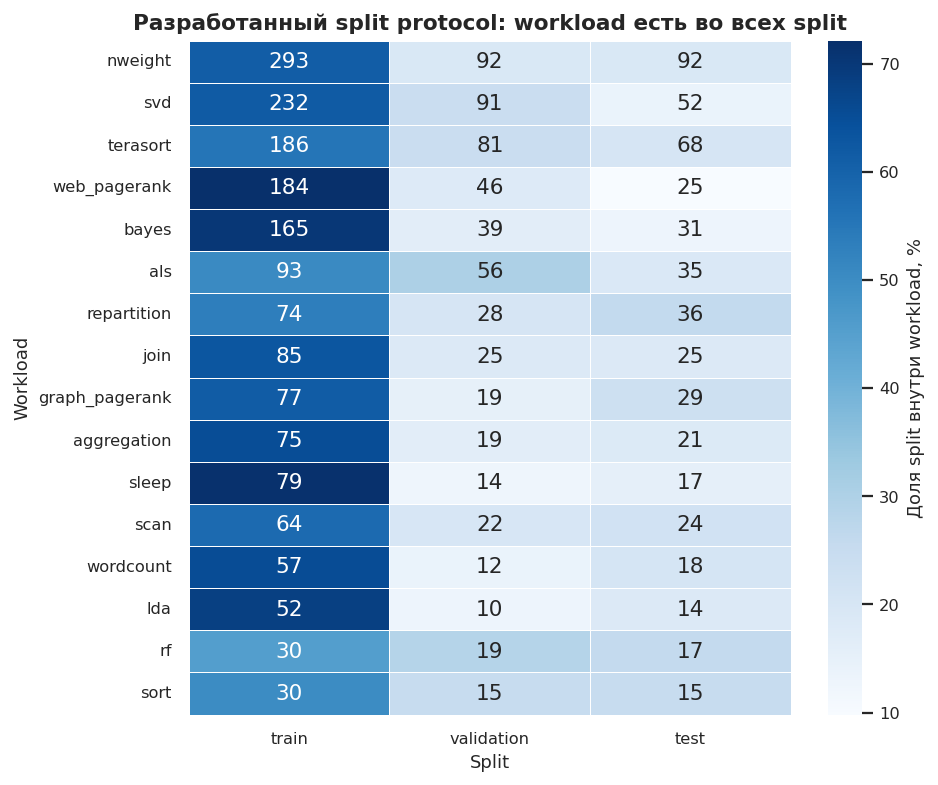

In [15]:
protocol_cfg = argparse.Namespace(
    validation_seed=PIPELINE_CONFIG["validation_seed"],
    validation_fraction=PIPELINE_CONFIG["validation_fraction"],
)
protocol_frame = make_protocol_frame(base_contract, PIPELINE_CONFIG["split_protocol"], protocol_cfg).copy()
protocol_frame["row_pos"] = np.arange(len(protocol_frame), dtype=np.int64)

protocol_split = (
    protocol_frame.groupby("split")
    .agg(Окна=("workload", "size"), Workload=("workload", "nunique"), Run_id=("run_id", "nunique"))
    .reindex(["train", "validation", "test"])
    .reset_index()
    .rename(columns={"split": "Protocol split"})
)
display(protocol_split.style.hide(axis="index"))

split_pivot = (
    protocol_frame.groupby(["workload", "split"]).size().unstack(fill_value=0)
    .reindex(columns=["train", "validation", "test"])
    .fillna(0)
    .astype(int)
)
split_pivot = split_pivot.loc[split_pivot.sum(axis=1).sort_values(ascending=False).index]
split_share = split_pivot.div(split_pivot.sum(axis=1), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(
    split_share * 100,
    annot=split_pivot,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Доля разбиения внутри типа нагрузки, %"},
    ax=ax,
)
ax.set_title("Разработанный протокол разбиения: типы нагрузки есть во всех разбиениях")
ax.set_xlabel("Разбиение")
ax.set_ylabel("Тип нагрузки")
plt.tight_layout()
plt.show()


На heatmap видно, что новый protocol split решает главную проблему исходного разбиения: все 16 workload теперь присутствуют в train, validation и test. После `stratified_by_workload` получается 1776 окон в train, 588 в validation и 519 в test. Внутри отдельных workload доли не идеально равны - например, `nweight`, `svd` и `terasort` остаются крупными источниками окон, - но ни один workload больше не выпадает полностью из validation или test.

Это полезная локальная победа pipeline. Теперь baseline в конце notebook проверяет не сценарий “модель впервые видит целый workload на test”, а более контролируемую задачу: может ли простой набор признаков обучаться на run-level split при сохранении всех workload. В `03` это же разбиение позволит сравнивать финальную модель с baseline без смены правил игры.


## 4. Собираем target matrix

Следующий слой pipeline - единая матрица целевых каналов. В исследовательском контуре мы фиксируем головы `y_warning` (как горизонт 180 с) и `horizon_30s/60s/120s/300s`, которые строятся из lead-time логики pipeline. Это важный момент: baseline в `02` и финальный контур в `03` должны решать один и тот же набор задач, иначе сравнение будет некорректным.


In [ ]:
target_matrix, target_manifest = make_target_matrix(protocol_frame, PIPELINE_CONFIG["targets"])
for target_idx, target_name in enumerate(PIPELINE_CONFIG["targets"]):
    protocol_frame[target_name] = target_matrix[:, target_idx].astype(int)

target_manifest_table = pd.DataFrame(
    [
        {
            "Target": label_target(name),
            "Кодовое имя": name,
            "Тип": info.get("type", ""),
            "Horizon sec": info.get("horizon_sec", ""),
            "Положительных окон": info.get("positives", ""),
        }
        for name, info in target_manifest.items()
        if isinstance(info, dict) and name in DISPLAY_TARGETS
    ]
)
display(target_manifest_table.style.hide(axis="index"))

plot_targets = [t for t in DISPLAY_TARGETS if t in protocol_frame.columns]
target_rates = (
    protocol_frame.groupby("split")[plot_targets]
    .mean()
    .reindex(["train", "validation", "test"])
    .T
)
target_rates.index = [label_target(t) for t in target_rates.index]

fig, ax = plt.subplots(figsize=(7.0, 4.8))
sns.heatmap(
    target_rates * 100,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Доля positive, %"},
    ax=ax,
)
ax.set_title("Плотность целевых каналов после протокольного разбиения")
ax.set_xlabel("Разбиение")
ax.set_ylabel("Целевой канал")
plt.tight_layout()
plt.show()


График плотности целевых каналов показывает, что новый split не делает задачу искусственно ровной. `horizon_30s` остается редким каналом, `horizon_60s` и `horizon_120s` занимают промежуточное положение, а `horizon_300s` и `y_warning` заметно плотнее. Это подтверждает, что раннее предупреждение объективно сложнее длинных горизонтов.

Это важный локальный вывод. В `02` пороги нельзя выбирать по test, потому что test имеет другую positive-density и может подсказать удобный threshold. Поэтому validation-based thresholding здесь не формальность, а защита эксперимента. В `03` финальная модель должна сравниваться при той же target matrix и той же логике выбора порогов.


## 5. Проектируем минимальные feature groups

Теперь задаем признаки для контрольных baseline. Это не поиск лучшей архитектуры. Нам нужны диагностические семейства, чтобы убедиться, что pipeline умеет работать с разными источниками: availability, logs, KPI и простым fused-вариантом. Более сложное взаимодействие модальностей сознательно оставляется для `03`.


In [17]:
feature_sets = baseline_feature_sets(protocol_frame)
feature_questions = {
    "availability_only": "проверить shortcut по доступности источников",
    "log_tfidf": "проверить событийный сигнал в логах",
    "metric_raw": "проверить абсолютные KPI-уровни",
    "metric_raw_plus_deviation": "проверить пользу простой динамики KPI",
    "fused_log_metric": "проверить простое объединение logs и KPI",
}

feature_table = pd.DataFrame(
    [
        {
            "Baseline family": label_baseline(name),
            "Кодовое имя": name,
            "Numeric columns": len(cols),
            "Text logs": "yes" if uses_text else "no",
            "Зачем включена": feature_questions[name],
        }
        for name, (cols, uses_text) in feature_sets.items()
    ]
)
display(feature_table.style.hide(axis="index"))


Baseline family,Кодовое имя,Numeric columns,Text logs,Зачем включена
logs,log_tfidf,14,yes,проверить событийный сигнал в логах
KPI raw,metric_raw,438,no,проверить абсолютные KPI-уровни
KPI + deviation,metric_raw_plus_deviation,1086,no,проверить пользу простой динамики KPI
logs + KPI,fused_log_metric,1099,yes,проверить простое объединение logs и KPI
availability,availability_only,6,no,проверить shortcut по доступности источников


Feature groups устроены намеренно несимметрично. KPI-группа широкая, потому что contract содержит много числовых признаков и deviation-каналов. Логовая группа компактнее и использует TF-IDF поверх `log_text` плюс агрегаты. `availability_only` выглядит почти слишком простой моделью, но она нужна: если доступность источников сама дает сильный baseline, значит pipeline должен учитывать этот shortcut в финальной интерпретации.


## 6. Обучаем контрольный baseline

Теперь pipeline получает свой первый полный прогон. Notebook запускает обучение baseline как часть собираемого протокола: текущий contract, текущий split protocol, текущий target set и текущие feature groups проходят через одну команду. Мы не переносим сюда все внутренности обучения по ячейкам, потому что задача notebook - показать, почему pipeline устроен именно так и какие выходы он должен произвести.

Сохраняемые файлы здесь - не финальный dashboard bundle. Это рабочие выходы pipeline: они нужны, чтобы следующий notebook мог сравнить финальную модель с тем же протоколом.


In [18]:
cmd = baseline_command()
display(Markdown("**Команда, которой notebook собирает baseline pipeline:**\n\n```powershell\n" + command_as_markdown(cmd) + "\n```"))

if EXECUTION_MODE == "build_and_train":
    run_command(cmd)
else:
    print("EXECUTION_MODE=reuse_last_run: используем последний baseline run без переобучения.")

metrics = numeric_metrics(read_csv(BASELINE_DIR / "baseline_protocol_metrics.csv"))
predictions = read_csv(BASELINE_DIR / "baseline_protocol_predictions.csv.gz")
workload_metrics = numeric_metrics(read_csv(BASELINE_DIR / "baseline_protocol_workload_metrics.csv"))
split_summary = read_csv(BASELINE_DIR / "baseline_protocol_split_summary.csv")
manifest = read_json(BASELINE_DIR / "baseline_protocol_manifest.json")

produced = pd.DataFrame(
    [
        ("metrics", "baseline_protocol_metrics.csv", len(metrics), "оценка validation/test по target и threshold policy"),
        ("predictions", "baseline_protocol_predictions.csv.gz", len(predictions), "score для error analysis и будущего сравнения"),
        ("workload metrics", "baseline_protocol_workload_metrics.csv", len(workload_metrics), "нормальный разбор доменных ошибок"),
        ("split summary", "baseline_protocol_split_summary.csv", len(split_summary), "фактический protocol split"),
        ("manifest", "baseline_protocol_manifest.json", 1 if manifest else 0, "конфигурация запуска и feature sets"),
    ],
    columns=["Выход pipeline", "Файл", "Строк", "Зачем нужен"],
)
display(produced.style.hide(axis="index"))


**Команда, которой notebook собирает baseline pipeline:**

```powershell
"c:\Users\ipopi\AppData\Local\Programs\Python\Python313\python.exe" `
  "-m" `
  "dashboard.training.baselines" `
  "--contract-path" `
  "c:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\contract\strict_intensity_contract.csv.gz" `
  "--output-dir" `
  "c:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\reports\protocol_fixed_baselines" `
  "--split-protocol" `
  "stratified_by_workload" `
  "--targets" `
  "default" `
  "--seed" `
  "43" `
  "--validation-seed" `
  "43" `
  "--validation-fraction" `
  "0.2" `
  "--fp-budget" `
  "0.1" `
  "--max-tfidf-features" `
  "2200" `
  "--max-iter" `
  "700"
```

{
  "status": "ok",
  "metrics": "dashboard\\artifacts\\reports\\protocol_fixed_baselines\\baseline_protocol_metrics.csv",
  "predictions": "dashboard\\artifacts\\reports\\protocol_fixed_baselines\\baseline_protocol_predictions.csv.gz",
  "workload_metrics": "dashboard\\artifacts\\reports\\protocol_fixed_baselines\\baseline_protocol_workload_metrics.csv",
  "split_summary": "dashboard\\artifacts\\reports\\protocol_fixed_baselines\\baseline_protocol_split_summary.csv",
  "manifest": "dashboard\\artifacts\\reports\\protocol_fixed_baselines\\baseline_protocol_manifest.json"
}



Выход pipeline,Файл,Строк,Зачем нужен
metrics,baseline_protocol_metrics.csv,140,оценка validation/test по target и threshold policy
predictions,baseline_protocol_predictions.csv.gz,38745,score для error analysis и будущего сравнения
workload metrics,baseline_protocol_workload_metrics.csv,560,нормальный разбор доменных ошибок
split summary,baseline_protocol_split_summary.csv,3,фактический protocol split
manifest,baseline_protocol_manifest.json,1,конфигурация запуска и feature sets


После этого шага pipeline уже не абстрактный. Он строит split, targets, feature groups, обучает простые модели и записывает результаты в формат, пригодный для следующего эксперимента. Baseline при этом остается маленьким: он нужен не как финальный результат, а как проверка, что цепочка действительно проходит от данных до predictions.


## 7. Acceptance gates для разработанного pipeline

Перед тем как смотреть на качество baseline, проверяем, что построенный pipeline вообще корректен. Эти gates ближе к разработческим acceptance criteria: мы только что собрали контур и убеждаемся, что он не нарушил базовые правила эксперимента.


In [ ]:
gates = []

required_contract_cols = {"workload", "run_id", "scenario", "window_ts", "window_end", "split", "y_warning", "minutes_before_fail", "log_available", "kpi_available"}
missing_contract = sorted(required_contract_cols - set(base_contract.columns))
add_gate(
    gates,
    "Contract layer",
    len(base_contract) > 0 and not missing_contract,
    f"{len(base_contract):,} rows; missing={missing_contract}",
    "единая оконная таблица существует и содержит ключевые поля",
)

split_counts = protocol_frame["split"].value_counts().reindex(["train", "validation", "test"]).fillna(0).astype(int)
add_gate(
    gates,
    "Protocol split",
    bool((split_counts > 0).all()),
    ", ".join(f"{name}={value}" for name, value in split_counts.items()),
    "train/validation/test можно использовать раздельно",
)

workload_coverage = protocol_frame.groupby("split")["workload"].nunique().reindex(["train", "validation", "test"]).fillna(0).astype(int)
add_gate(
    gates,
    "Workload coverage",
    bool((workload_coverage == protocol_frame["workload"].nunique()).all()),
    ", ".join(f"{name}={value}" for name, value in workload_coverage.items()),
    "каждый split содержит все workload",
)

row_sets = {split: set(protocol_frame.loc[protocol_frame["split"].eq(split), "row_pos"].astype(int)) for split in ["train", "validation", "test"]}
overlap = (row_sets["train"] & row_sets["validation"]) | (row_sets["train"] & row_sets["test"]) | (row_sets["validation"] & row_sets["test"])
add_gate(
    gates,
    "Split integrity",
    len(overlap) == 0 and protocol_frame["row_pos"].is_unique,
    f"overlap rows={len(overlap)}",
    "одно окно не попадает в несколько split",
)

display_target_ok = all(target in protocol_frame.columns for target in DISPLAY_TARGETS)
add_gate(
    gates,
    "Target matrix",
    display_target_ok,
    ", ".join(DISPLAY_TARGETS),
    "pipeline строит целевые головы для baseline и финальной модели",
)

expected_feature_groups = {"availability_only", "log_tfidf", "metric_raw", "metric_raw_plus_deviation", "fused_log_metric"}
add_gate(
    gates,
    "Feature groups",
    expected_feature_groups.issubset(feature_sets.keys()),
    ", ".join(sorted(feature_sets.keys())),
    "минимальный диагностический набор baseline задан",
)

manifest_cfg = manifest.get("config", {})
manifest_matches = (
    manifest_cfg.get("split_protocol") == PIPELINE_CONFIG["split_protocol"]
    and int(manifest_cfg.get("seed", -1)) == PIPELINE_CONFIG["seed"]
    and list(manifest_cfg.get("targets", [])) == PIPELINE_CONFIG["targets"]
)
add_gate(
    gates,
    "Run manifest",
    manifest_matches,
    f"split={manifest_cfg.get('split_protocol')}; seed={manifest_cfg.get('seed')}",
    "записанный run соответствует текущему notebook config",
)

prediction_cols = {"row_index", "run_id", "workload", "target_name", "target", "score", "baseline", "pred_split", "split_protocol"}
missing_pred = sorted(prediction_cols - set(predictions.columns))
expected_prediction_rows = (int((protocol_frame["split"] == "validation").sum()) + int((protocol_frame["split"] == "test").sum())) * len(expected_feature_groups) * len(PIPELINE_CONFIG["targets"])
add_gate(
    gates,
    "Prediction schema",
    not missing_pred and len(predictions) == expected_prediction_rows,
    f"rows={len(predictions):,}; expected={expected_prediction_rows:,}; missing={missing_pred}",
    "score-level сравнение возможно без переобучения",
)

threshold_ok = (
    not metrics.empty
    and set(metrics["threshold_policy"].dropna().astype(str).unique()) == {"validation_best_f1", f"validation_fp_budget_{PIPELINE_CONFIG['fp_budget']}"}
    and set(metrics["split"].dropna().astype(str).unique()) == {"validation", "test"}
)
add_gate(
    gates,
    "Threshold policy",
    threshold_ok,
    ", ".join(sorted(metrics["threshold_policy"].dropna().astype(str).unique())) if not metrics.empty else "none",
    "threshold выбирается на validation и переносится на test",
)

gate_table = pd.DataFrame(gates)
display(
    gate_table.style.hide(axis="index").apply(
        lambda col: ["color: #1F7A3A; font-weight: bold" if value == "OK" else "color: #B84A4A; font-weight: bold" for value in col]
        if col.name == "Status"
        else ["" for _ in col],
        axis=0,
    )
)

failed = gate_table.loc[gate_table["Status"].eq("FAIL")]
if not failed.empty:
    raise AssertionError("Pipeline acceptance gates failed: " + ", ".join(failed["Gate"].tolist()))


Acceptance gates проходят, значит разработанный pipeline можно считать рабочим экспериментальным контуром. Важно, что здесь проверяется не качество модели, а именно конструкция: split не пустой, workload представлены, target matrix создана, feature groups заданы, threshold policy не подглядывает в test, а predictions имеют схему, которую в `03` можно использовать без переобучения baseline.


## 8. Минимальный baseline как smoke test качества

Теперь baseline выполняет свою узкую роль: подтверждает, что pipeline не просто запускается, но и извлекает сигнал из данных. Мы не будем превращать этот раздел в длинный отчет о baseline. Достаточно посмотреть лучший простой baseline по каждому target и убедиться, что результаты осмысленны: длинные горизонты легче, ранние - шумнее, FP/FN уже видны.


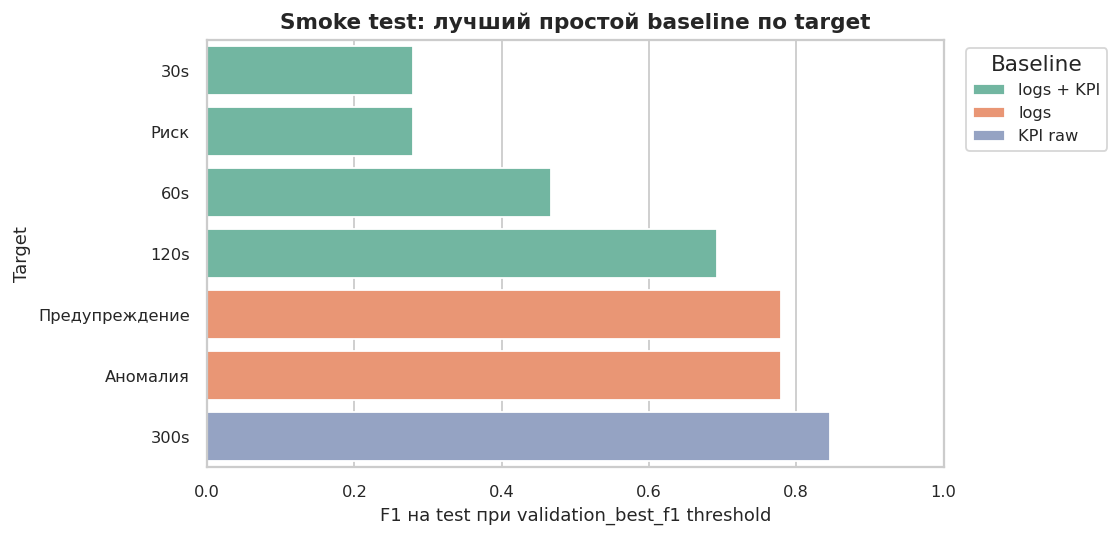

Target,Baseline,Precision,Recall,F1,AP,FP,FN
120s,logs + KPI,0.608,0.803,0.692,0.653,134,51
300s,KPI raw,0.772,0.936,0.846,0.920,99,23
30s,logs + KPI,0.186,0.571,0.280,0.205,158,27
60s,logs + KPI,0.361,0.660,0.466,0.360,172,50
Аномалия,logs,0.677,0.919,0.780,0.751,140,26
Риск,logs + KPI,0.186,0.571,0.280,0.205,158,27
Предупреждение,logs,0.677,0.919,0.780,0.751,140,26


In [20]:
test_metrics = metrics[
    metrics["split"].astype(str).eq("test")
    & metrics["threshold_policy"].astype(str).eq("validation_best_f1")
].copy()

best_by_target = (
    test_metrics.sort_values(["target", "f1", "average_precision"], ascending=[True, False, False])
    .groupby("target", as_index=False)
    .head(1)
    .copy()
)
best_by_target["Target"] = best_by_target["target"].map(label_target)
best_by_target["Baseline"] = best_by_target["baseline"].map(label_baseline)
best_by_target = best_by_target[best_by_target["target"].isin(DISPLAY_TARGETS)].copy()
best_by_target = best_by_target.sort_values("target")

fig, ax = plt.subplots(figsize=(8.8, 4.3))
plot_df = best_by_target.sort_values("f1", ascending=True)
sns.barplot(data=plot_df, x="f1", y="Target", hue="Baseline", dodge=False, palette="Set2", ax=ax)
ax.set_title("Проверка базовой модели: лучший результат по целевым каналам")
ax.set_xlabel("F1 на тесте (порог выбран по валидации)")
ax.set_ylabel("Целевой канал")
ax.set_xlim(0, 1.0)
ax.legend(title="Базовая модель", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

baseline_view = best_by_target[
    ["Target", "Baseline", "precision", "recall", "f1", "average_precision", "false_positives", "missed_anomalies"]
].rename(
    columns={
        "precision": "Точность",
        "recall": "Полнота",
        "f1": "F1",
        "average_precision": "AP",
        "false_positives": "FP",
        "missed_anomalies": "FN",
    }
)
display(
    baseline_view.style.hide(axis="index").format(
        {
            "Точность": "{:.3f}",
            "Полнота": "{:.3f}",
            "F1": "{:.3f}",
            "AP": "{:.3f}",
            "FP": "{:.0f}",
            "FN": "{:.0f}",
        }
    )
)


График smoke test показывает, что pipeline не просто запускается, а действительно извлекает сигнал. Самый стабильный результат ожидаемо у длинного горизонта `horizon_300s`, а ранние каналы (`horizon_30s`, `horizon_60s`) остаются самыми шумными и чувствительными к ложным срабатываниям. Канал `y_warning` дает промежуточный профиль: сигнал есть, но цена ошибок зависит от выбранного baseline-семейства.

Для `02` этого достаточно: baseline подтверждает, что собранный pipeline рабочий и данные содержат информативный сигнал. Одновременно он показывает ограничение простого подхода: чем раньше предупреждение, тем сильнее проявляется компромисс FP/FN. Поэтому в `03` финальная модель должна оправдывать сложность не общей победой по всем каналам, а более осмысленным ранним предупреждением и контролем FP.


## Что `02` передает дальше

Результат второго notebook - не “лучший baseline как финальная модель”, а разработанный protocol-fixed pipeline. Он собирает contract, применяет split protocol, строит target matrix, обучает диагностические baseline families, выбирает threshold на validation, оценивает test и сохраняет единый формат результатов.

Для `03_fused_model.ipynb` это означает следующее:

| Передается в `03` | Файл | Роль |
| --- | --- | --- |
| baseline metrics | `dashboard/artifacts/reports/protocol_fixed_baselines/baseline_protocol_metrics.csv` | контрольная точка качества по target |
| baseline predictions | `dashboard/artifacts/reports/protocol_fixed_baselines/baseline_protocol_predictions.csv.gz` | score-level сравнение и PR/threshold анализ |
| workload metrics | `dashboard/artifacts/reports/protocol_fixed_baselines/baseline_protocol_workload_metrics.csv` | проверка доменной устойчивости |
| manifest | `dashboard/artifacts/reports/protocol_fixed_baselines/baseline_protocol_manifest.json` | фиксация config, target set, feature groups и split protocol |

Главный вывод: pipeline в `02` готов для финального эксперимента, а baseline выполнил роль приемочного теста. Он показал, что данные не пустые, но простые модели слабо контролируют ранние ложные тревоги. В `03` финальный облегченный мультимодальный контур предупреждения будет строиться уже не как “еще один classifier”, а как финальный мультимодальный контур, который должен оправдать сложность через ранний warning, FP-control и пригодность к inference.
